<a href="https://colab.research.google.com/github/MadeOka06/PCVK_Ganjil_2026/blob/main/Praktikum10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#1.Persiapan dan Import Library

In [ ]:
# Import library yang dibutuhkan
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

# Akses drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#2. Enam Metode Template Matching (Kucing & Kelinci)

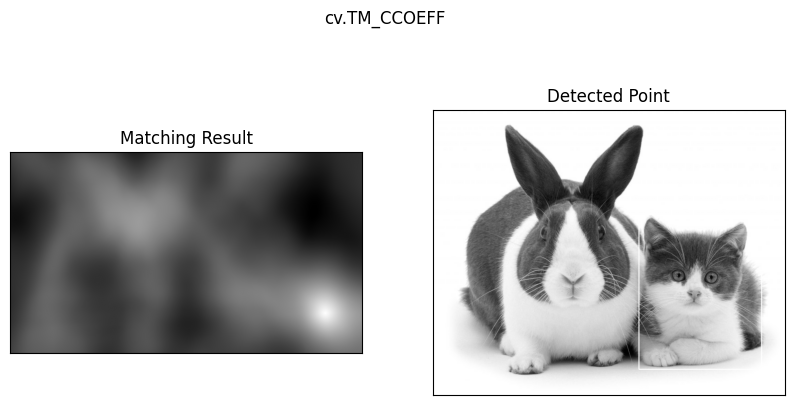

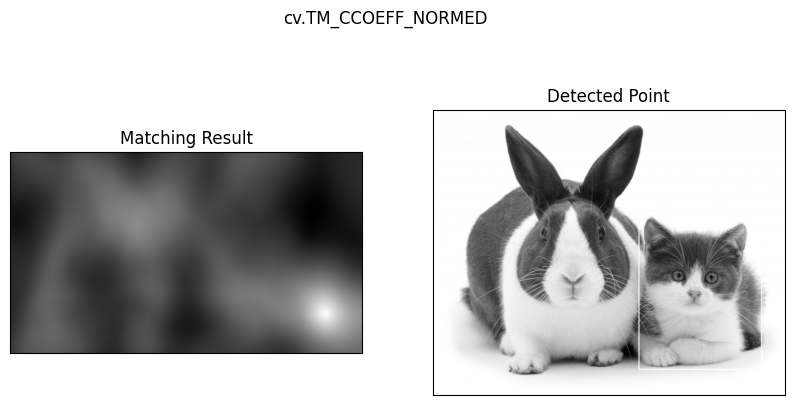

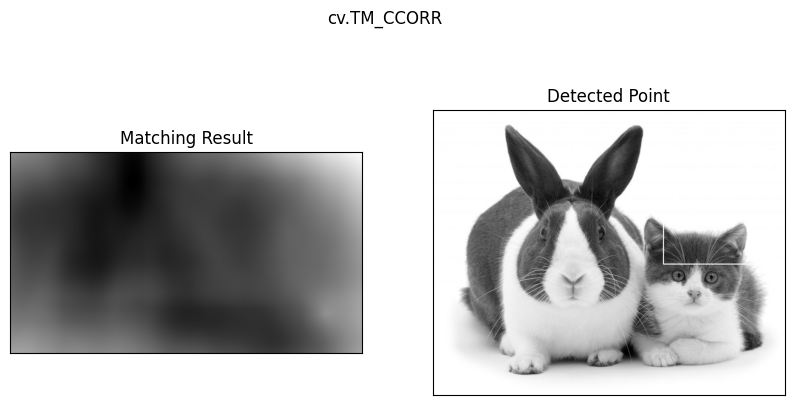

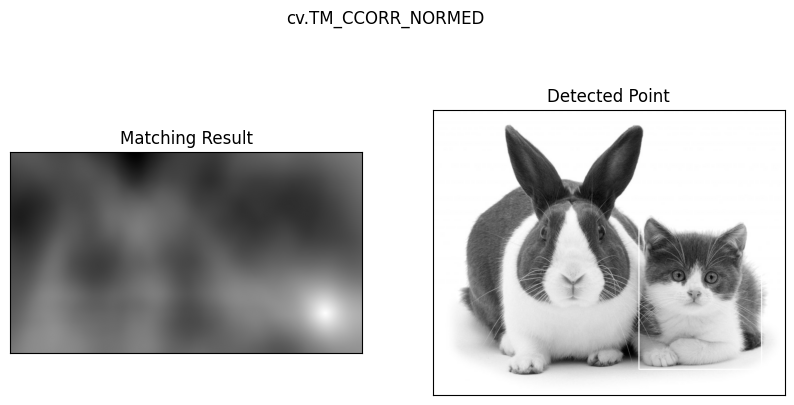

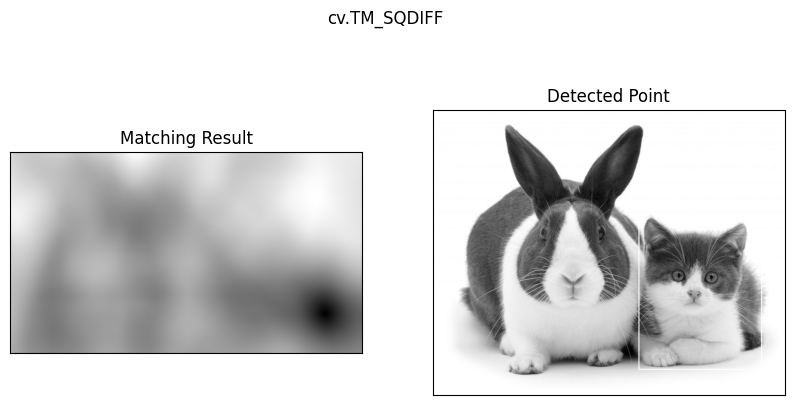

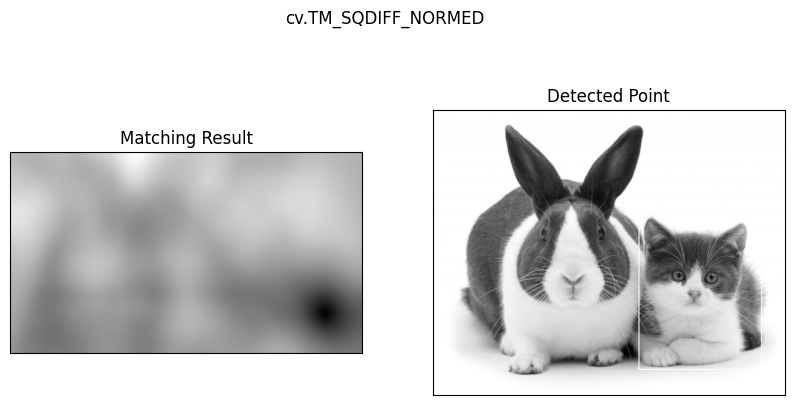

In [ ]:
img = cv.imread('/content/drive/MyDrive/PCVK/Images/cats_and_bunnies.jpg',0)
img2 = img.copy()
template = cv.imread('/content/drive/MyDrive/PCVK/Images/cat2_templatejpg.jpg',0)
w, h = template.shape[::-1]

# 6 Metode Template Matching di OpenCV
methods = ['cv.TM_CCOEFF', 'cv.TM_CCOEFF_NORMED', 'cv.TM_CCORR',
            'cv.TM_CCORR_NORMED', 'cv.TM_SQDIFF', 'cv.TM_SQDIFF_NORMED']

for meth in methods:
    img = img2.copy()
    method = eval(meth)

    # Menerapkan template Matching
    res = cv.matchTemplate(img, template, method)
    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(res)

    # Jika menggunakan TM_SQDIFF atau TM_SQDIFF_NORMED, ambil nilai minimum
    if method in [cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED]:
        top_left = min_loc
    else:
        top_left = max_loc
    bottom_right = (top_left[0] + w, top_left[1] + h)

    cv.rectangle(img, top_left, bottom_right, 255, 2)

    plt.figure(figsize=(10,5))
    plt.subplot(121), plt.imshow(res, cmap='gray')
    plt.title('Matching Result'), plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(img, cmap='gray')
    plt.title('Detected Point'), plt.xticks([]), plt.yticks([])
    plt.suptitle(meth)
    plt.show()

#3. Template Matching Multiple Object (Bahrain)

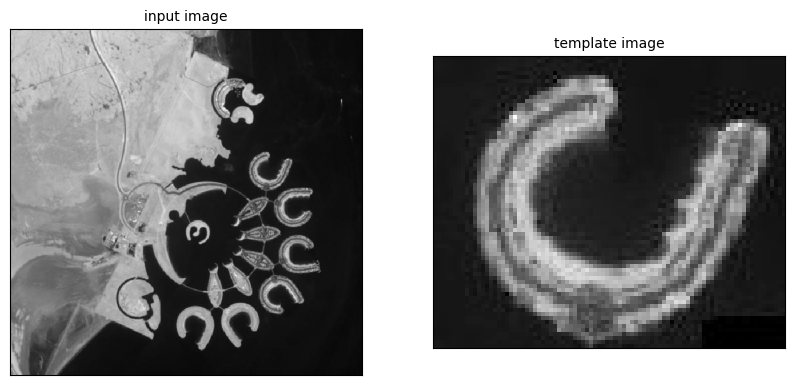

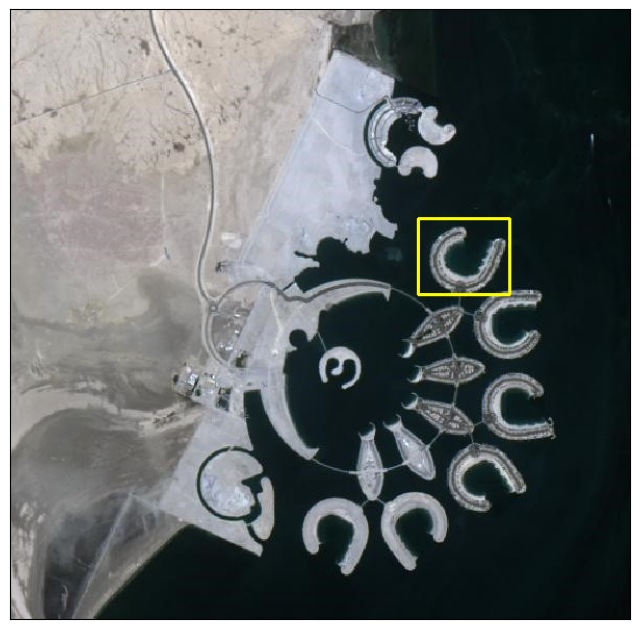

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. Baca citra masukan dan template
img_rgb = cv.imread('/content/drive/MyDrive/PCVK/Images/bahrain.jpg')
img_gray = cv.cvtColor(img_rgb, cv.COLOR_BGR2GRAY)
template = cv.imread('/content/drive/MyDrive/PCVK/Images/bahrain-template.jpg', 0)

# Ambil dimensi citra dan template
H, W = img_gray.shape
h, w = template.shape

# 2. Inisialisasi matriks hasil (R)
res = np.zeros((H - h + 1, W - w + 1))

img_gray_f = img_gray.astype(np.float32)
template_f = template.astype(np.float32)

temp_mean = np.mean(template_f)
temp_std = template_f - temp_mean
temp_var = np.sum(temp_std ** 2)

# 3. PROSES MANUAL TEMPLATE MATCHING (Sliding Window ZNCC)
for y in range(H - h + 1):
    for x in range(W - w + 1):
        roi = img_gray_f[y:y+h, x:x+w]

        roi_mean = np.mean(roi)
        roi_std = roi - roi_mean

        numerator = np.sum(temp_std * roi_std)
        denominator = np.sqrt(temp_var * np.sum(roi_std ** 2))

        if denominator == 0:
            res[y, x] = 0
        else:
            res[y, x] = numerator / denominator

# 4. Thresholding diturunkan menjadi 0.7 agar ke-6 objek terdeteksi
threshold = 0.7
loc = np.where(res >= threshold)

# 5. Gambarkan Bounding Box pada citra asli dengan warna kuning (0, 255, 255)
img_result = img_rgb.copy()

# Filter Overlap (Non-Maximum Suppression)
boxes = []
for pt in zip(*loc[::-1]):
    overlap = False
    for bx, by in boxes:
        # Jarak minimal antar kotak disesuaikan agar tidak saling menumpuk di 1 pulau
        if abs(pt[0] - bx) < w//2 and abs(pt[1] - by) < h//2:
            overlap = True
            break

    if not overlap:
        boxes.append(pt)
        cv.rectangle(img_result, pt, (pt[0] + w, pt[1] + h), (0, 255, 255), 2)

# 6. Menampilkan Hasil
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_gray, cmap='gray')
plt.title('input image', fontsize=10), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(template, cmap='gray')
plt.title('template image', fontsize=10), plt.xticks([]), plt.yticks([])
plt.show()

plt.figure(figsize=(8, 8))
plt.imshow(cv.cvtColor(img_result, cv.COLOR_BGR2RGB))
plt.xticks([]), plt.yticks([])
plt.show()

#4. Edge Detection (Sobel, Canny, Laplacian)

/usr/local/lib/python3.13/dist-packages/matplotlib/colors.py:2293: RuntimeWarning: invalid value encountered in subtract
  resdat -= vmin


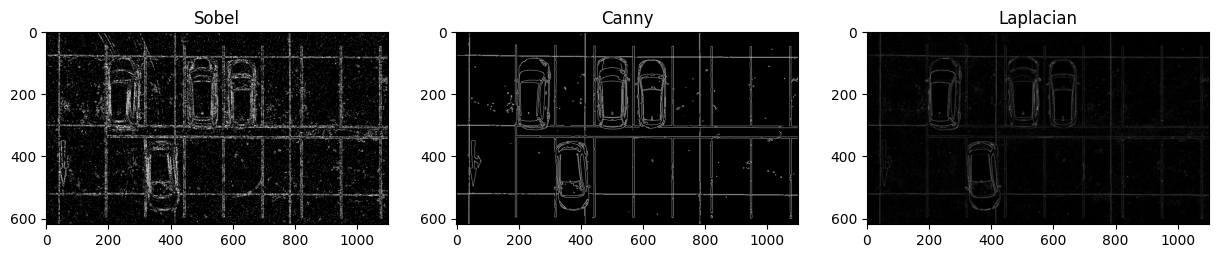

In [ ]:
img = cv.imread('/content/drive/MyDrive/PCVK/Images/car-park.jpg',0)

# a. Sobel Edge Detection
sobelx = cv.Sobel(img, cv.CV_64F, 1, 0, ksize=5)
sobely = cv.Sobel(img, cv.CV_64F, 0, 1, ksize=5)
sobel_combined = cv.bitwise_or(np.absolute(sobelx), np.absolute(sobely))

# b. Canny Edge Detection
edges_canny = cv.Canny(img, 100, 200)

# c. Laplacian Edge Detection
laplacian = cv.Laplacian(img, cv.CV_64F)
laplacian_abs = np.absolute(laplacian)

plt.figure(figsize=(15,5))
plt.subplot(131), plt.imshow(sobel_combined, cmap='gray'), plt.title('Sobel')
plt.subplot(132), plt.imshow(edges_canny, cmap='gray'), plt.title('Canny')
plt.subplot(133), plt.imshow(laplacian_abs, cmap='gray'), plt.title('Laplacian')
plt.show()

#5. Corner Detection (Harris & Shi-Tomasi)

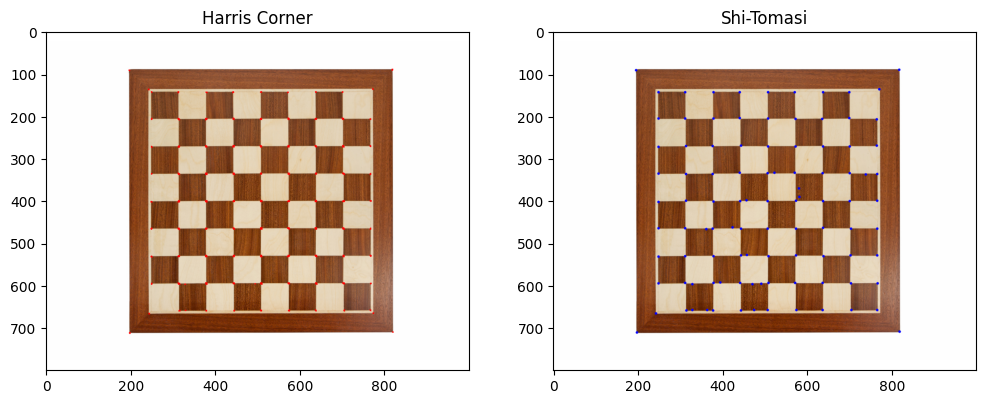

In [ ]:
img = cv.imread('/content/drive/MyDrive/PCVK/Images/chess-board.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
gray = np.float32(gray)

# a. Harris Corner Detection
dst = cv.cornerHarris(gray, 2, 3, 0.04)
dst = cv.dilate(dst, None)
img_harris = img.copy()
img_harris[dst > 0.01 * dst.max()] = [0, 0, 255] # Titik merah

# b. Shi-Tomasi Detection
corners = cv.goodFeaturesToTrack(gray, 100, 0.01, 10)
corners = np.intp(corners)
img_shi = img.copy()
for i in corners:
    x, y = i.ravel()
    cv.circle(img_shi, (x, y), 3, 255, -1) # Titik biru

plt.figure(figsize=(12,6))
plt.subplot(121), plt.imshow(cv.cvtColor(img_harris, cv.COLOR_BGR2RGB)), plt.title('Harris Corner')
plt.subplot(122), plt.imshow(cv.cvtColor(img_shi, cv.COLOR_BGR2RGB)), plt.title('Shi-Tomasi')
plt.show()

#6. Hough Transform (Grid Detection - Sudoku)

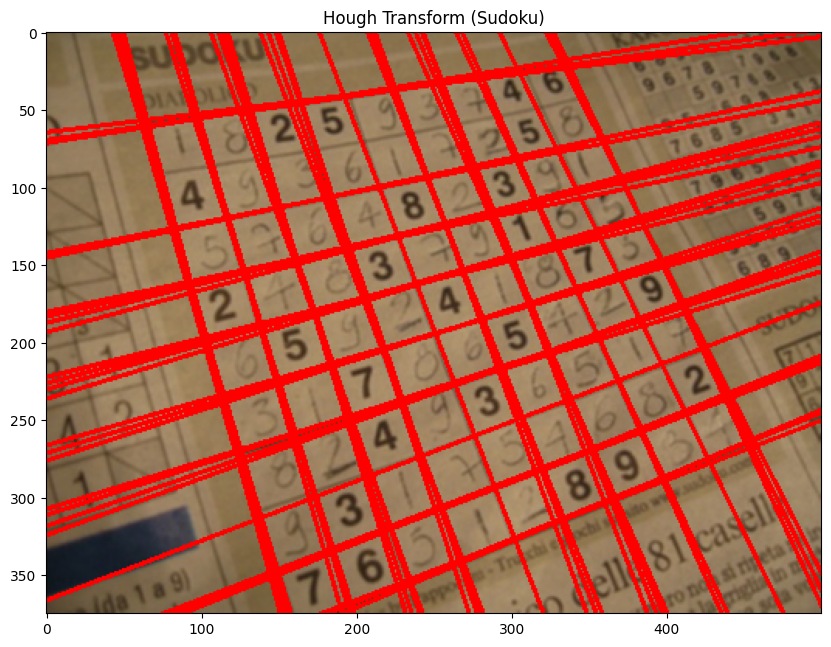

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. Baca gambar dan ubah ke grayscale
img = cv.imread('/content/drive/MyDrive/PCVK/Images/sudoku.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Tambahan: Aplikasikan Gaussian Blur untuk menyamarkan tekstur kertas (noise)
blur = cv.GaussianBlur(gray, (5, 5), 0)

# 2. Terapkan Canny Edge Detection pada citra yang sudah diblur
edges = cv.Canny(blur, 50, 150, apertureSize=3)

# 3. Dilasi dan Erosi (Sesuai modul)
kernel = np.ones((3,3), np.uint8)
dilated_edges = cv.dilate(edges, kernel, iterations=1)
eroded_edges = cv.erode(dilated_edges, kernel, iterations=1)

# 4. Menerapkan HoughLines
# NAIKKAN nilai threshold (misal 200 atau 250) agar hanya garis lurus yang kuat yang terdeteksi
lines = cv.HoughLines(eroded_edges, 1, np.pi/180, 200)

# 5. Menggambar garis pada gambar asli
if lines is not None:
    for line in lines:
        rho, theta = line[0]
        a = np.cos(theta)
        b = np.sin(theta)
        x0 = a * rho
        y0 = b * rho
        x1 = int(x0 + 1000*(-b))
        y1 = int(y0 + 1000*(a))
        x2 = int(x0 - 1000*(-b))
        y2 = int(y0 - 1000*(a))
        cv.line(img, (x1, y1), (x2, y2), (0, 0, 255), 2)

# Tampilkan hasil
plt.figure(figsize=(10, 10))
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Hough Transform (Sudoku)')
plt.show()

#7. Contour Detection (Laptop)

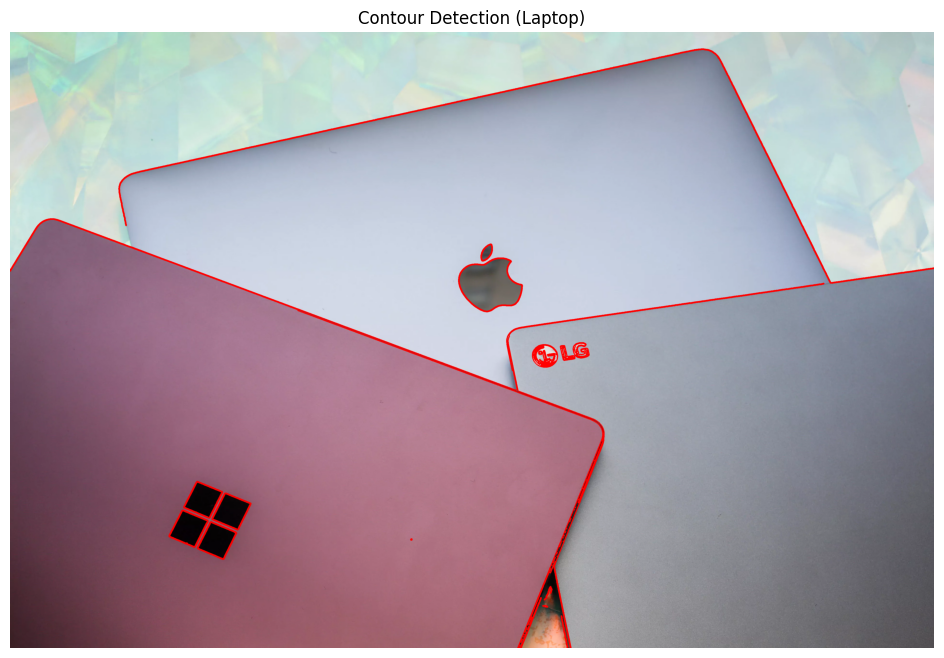

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. Baca gambar
img = cv.imread('/content/drive/MyDrive/PCVK/Images/laptop.jpg')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# 2. Preprocessing dengan Gaussian Blur untuk mengurangi noise
blur = cv.GaussianBlur(img_gray, (5, 5), 0)

# 3. Terapkan Canny Edge Detection
edges = cv.Canny(blur, 50, 150)

# 4. Dilasi sedikit agar garis tepi yang terputus bisa menyambung
kernel = np.ones((3,3), np.uint8)
edges_dilated = cv.dilate(edges, kernel, iterations=1)

# 5. Temukan kontur
# Menggunakan RETR_TREE agar kontur di dalam objek (seperti logo) juga terdeteksi
contours, hierarchy = cv.findContours(edges_dilated, cv.RETR_TREE, cv.CHAIN_APPROX_SIMPLE)

# 6. Gambar kontur pada citra asli
# Gunakan warna Merah (0, 0, 255) dalam format BGR dan ketebalan garis 3
cv.drawContours(img, contours, -1, (0, 0, 255), 3)

# 7. Tampilkan hasil
plt.figure(figsize=(12, 8))
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Contour Detection (Laptop)')
plt.axis('off')
plt.show()

#D2. Praktikum Feature Matching dan Face Detection
#8. Face Detection (Berbagai Objek)

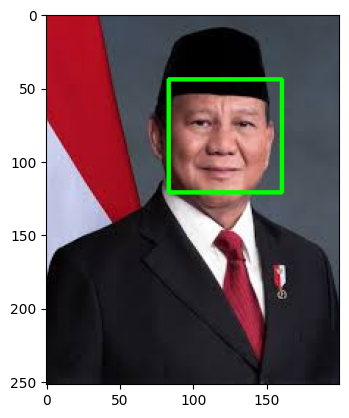

In [ ]:
cascade_wajah = cv.CascadeClassifier('/content/drive/MyDrive/PCVK/Images/haarcascades/haarcascade_frontalface_alt.xml')

# Contoh untuk satu gambar (Lakukan iterasi atau copy untuk gambar Kartini/Orang bermasker)
img_face = cv.imread('/content/drive/MyDrive/PCVK/Images/facedet/prabowo.jpg')
gray_face = cv.cvtColor(img_face, cv.COLOR_BGR2GRAY)

roi_wajah = cascade_wajah.detectMultiScale(gray_face, scaleFactor=1.1, minNeighbors=5)
for (x, y, w, h) in roi_wajah:
    cv.rectangle(img_face, (x, y), (x+w, y+h), (0, 255, 0), 2)

plt.imshow(cv.cvtColor(img_face, cv.COLOR_BGR2RGB))
plt.show()

#9. Deteksi Wajah Kucing

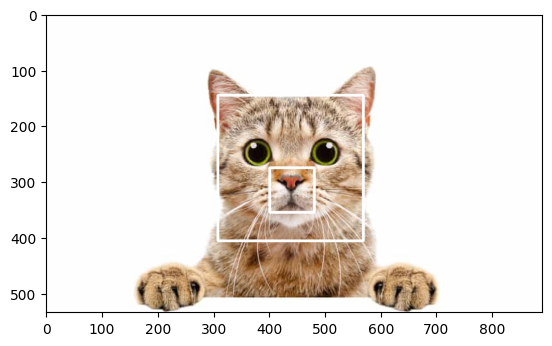

In [ ]:
cascade_kucing = cv.CascadeClassifier('/content/drive/MyDrive/PCVK/Images/haarcascades/haarcascade_frontalcatface.xml')
img_cat = cv.imread('/content/drive/MyDrive/PCVK/Images/facedet/kucing.jpg')
gray_cat = cv.cvtColor(img_cat, cv.COLOR_BGR2GRAY)

roi_kucing = cascade_kucing.detectMultiScale(gray_cat, 1.1, 3)
for (x,y,w,h) in roi_kucing:
    cv.rectangle(img_cat, (x,y), (x+w, y+h), (255,255,255), 3)

plt.imshow(cv.cvtColor(img_cat, cv.COLOR_BGR2RGB))
plt.show()

#10 & 11. Deteksi Mata & Senyum

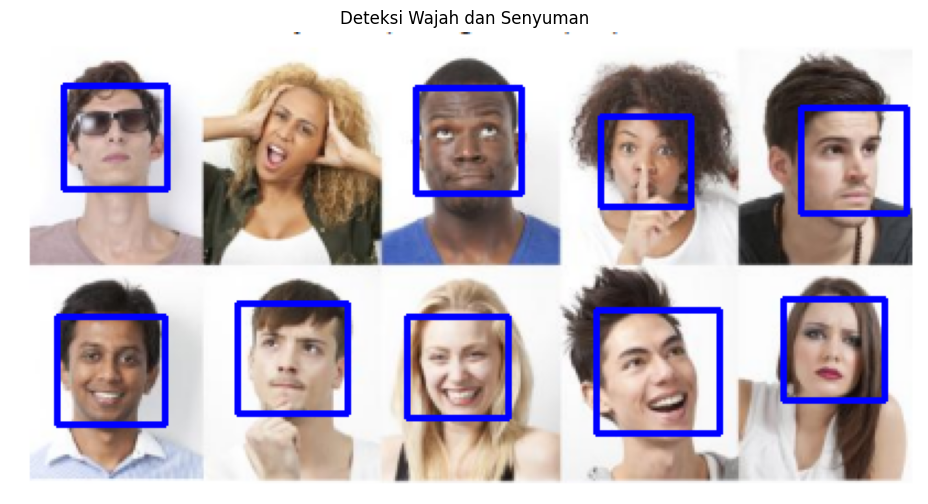

In [ ]:
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

# Load pretrained Haarcascade untuk wajah dan senyum
# Sesuaikan path direktori Anda
cascade_wajah = cv.CascadeClassifier('/content/drive/MyDrive/PCVK/Images/haarcascades/haarcascade_frontalface_alt.xml')
cascade_senyum = cv.CascadeClassifier('/content/drive/MyDrive/PCVK/Images/haarcascades/haarcascade_smile.xml')

# Baca gambar people
img_people = cv.imread('/content/drive/MyDrive/PCVK/Images/facedet/people.jpg')
gray_people = cv.cvtColor(img_people, cv.COLOR_BGR2GRAY)

# Deteksi wajah terlebih dahulu
wajah = cascade_wajah.detectMultiScale(gray_people, scaleFactor=1.1, minNeighbors=5)

for (x, y, w, h) in wajah:
    # 1. Gambar kotak wajah terlebih dahulu (warna biru) untuk memastikan wajah terdeteksi
    cv.rectangle(img_people, (x, y), (x+w, y+h), (255, 0, 0), 2)

    # Buat ROI (Region of Interest)
    roi_gray = gray_people[y:y+h, x:x+w]
    roi_color = img_people[y:y+h, x:x+w]

    # 2. Longgarkan parameter deteksi senyum
    senyum = cascade_senyum.detectMultiScale(roi_gray, scaleFactor=1.3, minNeighbors=7)

    for (sx, sy, sw, sh) in senyum:
        # Gambar kotak merah dan tulisan "Senyum"
        cv.rectangle(roi_color, (sx, sy), (sx+sw, sy+sh), (0, 0, 255), 2)
        cv.putText(roi_color, 'Senyum', (sx, sy-10), cv.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)
# Tampilkan hasil
plt.figure(figsize=(12, 6))
plt.imshow(cv.cvtColor(img_people, cv.COLOR_BGR2RGB))
plt.title('Deteksi Wajah dan Senyuman')
plt.axis('off')
plt.show()

#13. Blurring Wajah

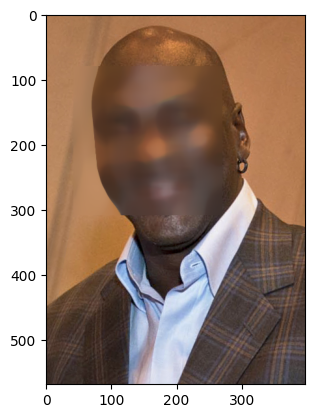

In [ ]:
img_blur = cv.imread('/content/drive/MyDrive/PCVK/Images/facedet/mjordan.jpg')
gray_blur = cv.cvtColor(img_blur, cv.COLOR_BGR2GRAY)
roi_wajah = cascade_wajah.detectMultiScale(gray_blur, 1.1, 5)

for (x, y, w, h) in roi_wajah:
    roi = img_blur[y:y+h, x:x+w]
    roi_blurred = cv.medianBlur(roi, 35) # Gunakan cv.medianBlur
    img_blur[y:y+h, x:x+w] = roi_blurred

plt.imshow(cv.cvtColor(img_blur, cv.COLOR_BGR2RGB))
plt.show()

#14. Pengolahan KTM (Feature Matching)

Ukuran gambar KTM (tinggi, lebar): (1014, 1600)


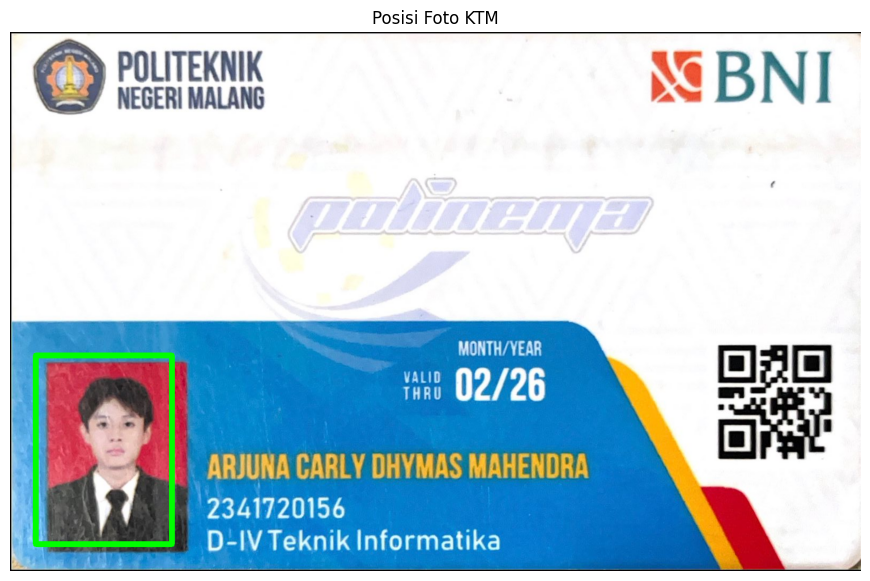

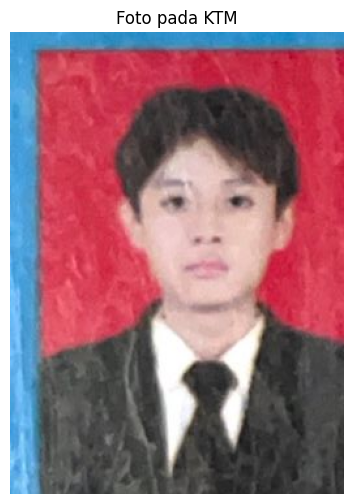

Ukuran foto KTM: (355, 256)


In [ ]:
import cv2
import matplotlib.pyplot as plt

ktm_path = '/content/drive/MyDrive/PCVK/Images/ktm.jpeg'

# Membaca gambar KTM
ktm_color = cv2.imread(ktm_path, cv2.IMREAD_COLOR)

if ktm_color is None:
    raise FileNotFoundError("Gambar KTM tidak ditemukan!")

# a. Mendapatkan ukuran gambar
height, width = ktm_color.shape[:2]

print('Ukuran gambar KTM (tinggi, lebar):', (height, width))

# b. Menentukan koordinat foto KTM
# Koordinat menggunakan persentase ukuran gambar
x1 = int(0.03 * width)
y1 = int(0.60 * height)
x2 = int(0.19 * width)
y2 = int(0.95 * height)

PHOTO_BOX = (x1, y1, x2, y2)

# Membuat kotak penanda posisi foto
ktm_preview = ktm_color.copy()

cv2.rectangle(
    ktm_preview,
    (x1, y1),
    (x2, y2),
    (0, 255, 0),
    10
)

# Menampilkan posisi kotak foto
plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(ktm_preview, cv2.COLOR_BGR2RGB))
plt.title('Posisi Foto KTM')
plt.axis('off')
plt.show()

# Melakukan cropping foto KTM
ktm_photo = ktm_color[y1:y2, x1:x2]

# Menampilkan hasil cropping
plt.figure(figsize=(5, 6))
plt.imshow(cv2.cvtColor(ktm_photo, cv2.COLOR_BGR2RGB))
plt.title('Foto pada KTM')
plt.axis('off')
plt.show()

print('Ukuran foto KTM:', ktm_photo.shape[:2])

#D3. Tugas Pengayaan (Pengenalan Karakter KTM dengan CNN)
#A. Persiapan Dataset / Training Data

In [ ]:
import os
import cv2
import random
import numpy as np
import pickle
from tqdm import tqdm

DATADIR = "/content/drive/MyDrive/PCVK/Images/dataset/testing"
width, height = 100, 100
dirs = sorted(os.listdir(DATADIR))
training_data = []

for char_name in dirs:
    path = os.path.join(DATADIR, char_name)
    class_number = dirs.index(char_name)
    for img in tqdm(os.listdir(path), desc=char_name):
        try:
            img_array = cv2.imread(os.path.join(path, img), cv2.IMREAD_GRAYSCALE)
            new_array = cv2.resize(img_array, (width, height))
            training_data.append([new_array, class_number])
        except Exception:
            pass

random.shuffle(training_data)
X, Y = [], []
for feature, label in training_data:
    X.append(feature)
    Y.append(label)

X = np.array(X).reshape(-1, width, height, 1)
Y = np.array(Y)

pickle.dump(X, open("X.pickle", "wb"))
pickle.dump(Y, open("Y.pickle", "wb"))
pickle.dump(dirs, open("kelas.pickle", "wb"))

print("jumlah data :", len(training_data))
print("jumlah kelas:", len(dirs), dirs)

car1: 100%|██████████| 10/10 [00:04<00:00,  2.30it/s]

jumlah data : 10
jumlah kelas: 1 ['car1']


#B. Membangun & Latih Model CNN

In [ ]:
import pickle
from keras.layers import (Input, Conv2D, MaxPooling2D, Flatten, Dense, ZeroPadding2D)
from keras.models import Model
from keras.optimizers import Adam
from keras.utils import to_categorical

X = pickle.load(open("X.pickle", "rb"))
Y = pickle.load(open("Y.pickle", "rb"))
Y = to_categorical(Y)
X = X / 255.0
width, height = 100, 100
jumlah_kelas = Y.shape[1]

inputs = Input(shape=(width, height, 1))
conv_layer = ZeroPadding2D(padding=(2, 2))(inputs)
conv_layer = Conv2D(16, (5, 5), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(64, (3, 3), strides=(1, 1), activation='relu')(conv_layer)

flaten = Flatten()(conv_layer)
fc_layer = Dense(256, activation='relu')(flaten)
fc_layer = Dense(64, activation='relu')(fc_layer)
outputs = Dense(jumlah_kelas, activation='softmax')(fc_layer)

model = Model(inputs=inputs, outputs=outputs)
model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

riwayat = model.fit(X, Y, epochs=20, verbose=1, validation_split=0.2)
model.save('anpr.keras')
print("akurasi training:", riwayat.history['accuracy'][-1])
print("akurasi validasi:", riwayat.history['val_accuracy'][-1])

Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/ops/nn.py:947: UserWarning: You are using a softmax over axis -1 of a tensor of shape (None, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/keras/src/losses/losses.py:33: SyntaxWarning: In loss categorical_crossentropy, expected y_pred.shape to be (batch_size, num_classes) with num_classes > 1. Received: y_pred.shape=(None, 1). Consider using 'binary_crossentropy' if you only have 2 classes.
  return self.fn(y_true, y_pred, **self._fn_kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 2/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 3/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 4/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 5/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 6/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 989ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 7/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 742ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 8/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 653ms/step - accuracy: 1.0000 - loss: 0.0000e+00 

#C. Testing Data Prediksi Karakter

In [ ]:
import os
import cv2
import pickle
import numpy as np
import tensorflow as tf

data_dir_testing = "/content/drive/MyDrive/PCVK/Images/dataset/training"
width, height = 100, 100
model = tf.keras.models.load_model("anpr.keras")
dirs = pickle.load(open("kelas.pickle", "rb"))

for car in sorted(os.listdir(data_dir_testing)):
    temp = ""
    folder = os.path.join(data_dir_testing, car)
    for char_img in sorted(os.listdir(folder)):
        img_array = cv2.imread(os.path.join(folder, char_img), cv2.IMREAD_GRAYSCALE)
        new_array = cv2.resize(img_array, (width, height))
        new_array = new_array.reshape(-1, width, height, 1) / 255.0
        prediction = model.predict(new_array, verbose=0)
        temp += dirs[np.argmax(prediction[0])]
    print("folder name: {} no: {}".format(car, temp))

/usr/local/lib/python3.13/dist-packages/keras/src/ops/nn.py:947: UserWarning: You are using a softmax over axis -1 of a tensor of shape (1, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(


folder name: 0 no: car1car1car1car1car1
folder name: 1 no: car1car1car1car1car1
folder name: 2 no: car1car1car1car1car1
folder name: 3 no: car1car1car1car1car1
folder name: 4 no: car1car1car1car1car1
folder name: 5 no: car1car1car1car1car1
folder name: 6 no: car1car1car1car1car1
folder name: 7 no: car1car1car1car1car1
folder name: 8 no: car1car1car1car1car1
folder name: 9 no: car1car1car1car1car1


In [ ]:
import io
import cv2 as cv
import numpy as np
import PIL.Image
from base64 import b64decode, b64encode
from IPython.display import display, Javascript
from google.colab.output import eval_js

def js_to_image(js_reply):
    image_bytes = b64decode(js_reply.split(',')[1])
    jpg_as_np = np.frombuffer(image_bytes, dtype=np.uint8)
    img = cv.imdecode(jpg_as_np, flags=1)
    return img

def bbox_to_bytes(bbox_array):
    bbox_PIL = PIL.Image.fromarray(bbox_array, 'RGBA')
    iobuf = io.BytesIO()
    bbox_PIL.save(iobuf, format='png')
    bbox_bytes = 'data:image/png;base64,{}'.format((str(b64encode(iobuf.getvalue()), 'utf-8')))
    return bbox_bytes

def video_stream():
    js = Javascript('''
        var video;
        var div = null;
        var stream;
        var captureCanvas;
        var imgElement;
        var labelElement;
        var pendingResolve = null;
        var shutdown = false;

        function removeDom() {
           stream.getVideoTracks()[0].stop();
           video.remove();
           div.remove();
           video = null;
           div = null;
           stream = null;
           imgElement = null;
           captureCanvas = null;
           labelElement = null;
        }

        function onAnimationFrame() {
          if (!shutdown) {
            window.requestAnimationFrame(onAnimationFrame);
          }
          if (pendingResolve) {
            var result = "";
            if (!shutdown) {
              captureCanvas.getContext('2d').drawImage(video, 0, 0, 640, 480);
              result = captureCanvas.toDataURL('image/jpeg', 0.8)
            }
            var lp = pendingResolve;
            pendingResolve = null;
            lp(result);
          }
        }

        async function createDom() {
          if (div !== null) {
            return stream;
          }
          div = document.createElement('div');
          div.style.border = '2px solid black';
          div.style.padding = '3px';
          div.style.width = '100%';
          div.style.maxWidth = '600px';
          document.body.appendChild(div);

          const modelOut = document.createElement('div');
          modelOut.innerHTML = "<span>Status: </span>";
          labelElement = document.createElement('span');
          labelElement.innerText = 'No data';
          labelElement.style.fontWeight = 'bold';
          modelOut.appendChild(labelElement);
          div.appendChild(modelOut);

          video = document.createElement('video');
          video.style.display = 'block';
          video.width = div.clientWidth - 6;
          video.setAttribute('playsinline', '');
          video.onclick = () => { shutdown = true; };
          stream = await navigator.mediaDevices.getUserMedia(
              {video: { facingMode: "environment"}});
          div.appendChild(video);

          imgElement = document.createElement('img');
          imgElement.style.position = 'absolute';
          imgElement.style.zIndex = 1;
          imgElement.onclick = () => { shutdown = true; };
          div.appendChild(imgElement);

          const instruction = document.createElement('div');
          instruction.innerHTML =
              '<span style="color: red; font-weight: bold;">' +
              'Klik video untuk menghentikan kamera</span>';
          div.appendChild(instruction);
          instruction.onclick = () => { shutdown = true; };

          video.srcObject = stream;
          await video.play();

          captureCanvas = document.createElement('canvas');
          captureCanvas.width = 640;
          captureCanvas.height = 480;
          window.requestAnimationFrame(onAnimationFrame);
          return stream;
        }
        async function stream_frame(label, imgData) {
          if (shutdown) {
            removeDom();
            shutdown = false;
            return '';
          }
          var preCreate = Date.now();
          stream = await createDom();
          var preShow = Date.now();
          if (label != "") {
            labelElement.innerHTML = label;
          }
          if (imgData != "") {
            var videoRect = video.getClientRects()[0];
            imgElement.style.top = videoRect.top + "px";
            imgElement.style.left = videoRect.left + "px";
            imgElement.style.width = videoRect.width + "px";
            imgElement.style.height = videoRect.height + "px";
            imgElement.src = imgData;
          }
          var preCapture = Date.now();
          var result = await new Promise(function(resolve, reject) {
            pendingResolve = resolve;
          });
          shutdown = false;
          return {'create': preShow - preCreate,
                  'show': preCapture - preShow,
                  'capture': Date.now() - preCapture,
                  'img': result};
        }
        ''')
    display(js)

def video_frame(label, bbox):
    data = eval_js('stream_frame("{}", "{}")'.format(label, bbox))
    return data

face_cascade = cv.CascadeClassifier(cv.data.haarcascades + 'haarcascade_frontalface_default.xml')

try:
    video_stream()
    label_html = 'Capturing...'
    bbox = ''
    while True:
        js_reply = video_frame(label_html, bbox)
        if not js_reply:
            break
        img = js_to_image(js_reply["img"])
        bbox_array = np.zeros([480, 640, 4], dtype=np.uint8)
        gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
        faces = face_cascade.detectMultiScale(gray)
        for (x, y, w, h) in faces:
            bbox_array = cv.rectangle(bbox_array, (x, y), (x + w, y + h), (255, 0, 0), 2)
        bbox_array[:, :, 3] = (bbox_array.max(axis=2) > 0).astype(int) * 255
        bbox = bbox_to_bytes(bbox_array)
except Exception as e:
    print("Kamera tidak aktif / dihentikan:", e)

<IPython.core.display.Javascript object>

/tmp/ipykernel_1849/11637206.py:16: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  bbox_PIL = PIL.Image.fromarray(bbox_array, 'RGBA')
